Actual Distribution:
Mild Dementia: 5002
Moderate Dementia: 488
Non Demented: 67222
Very mild Dementia: 13725


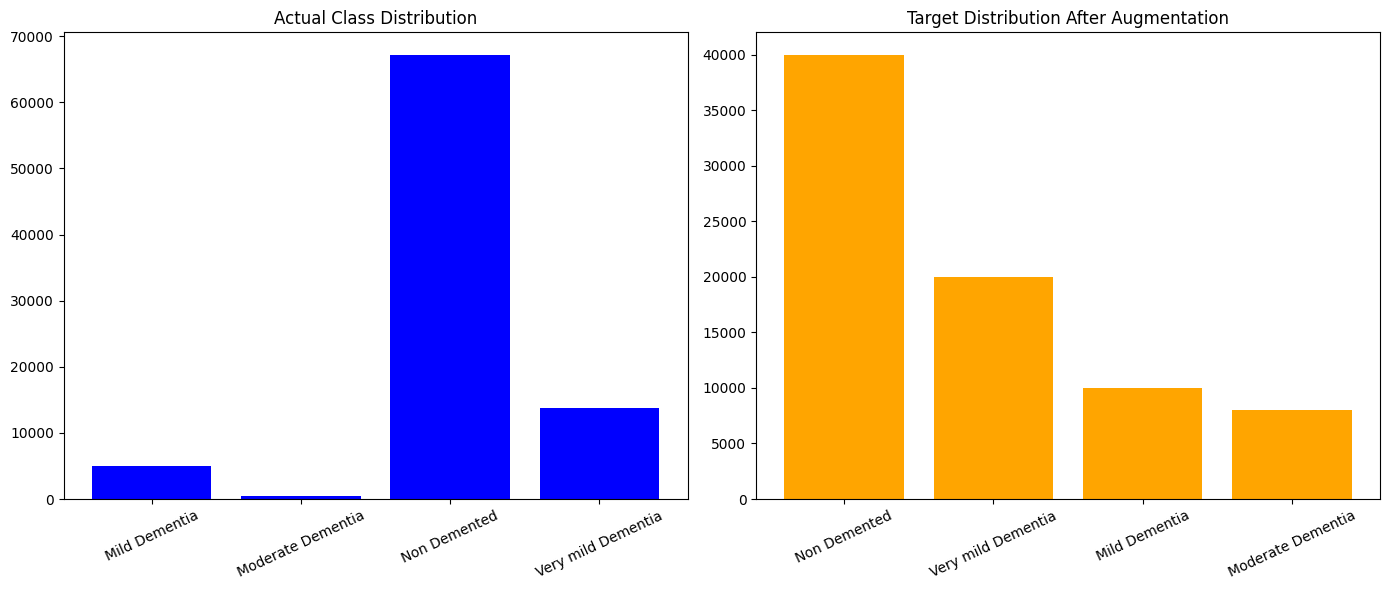

In [1]:
import os
import matplotlib.pyplot as plt

# Your dataset path
DATASET_DIR = r"C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Data"

# Class names must match your folder names EXACTLY
classes = [
    "Mild Dementia",
    "Moderate Dementia",
    "Non Demented",
    "Very mild Dementia"
]

# Count images in each folder
class_counts = {}
for cls in classes:
    folder_path = os.path.join(DATASET_DIR, cls)
    if os.path.exists(folder_path):
        count = len(os.listdir(folder_path))
        class_counts[cls] = count
    else:
        class_counts[cls] = 0

print("Actual Distribution:")
for k,v in class_counts.items():
    print(f"{k}: {v}")

# Your target distribution (example)
target_counts = {
    "Non Demented": 40000,
    "Very mild Dementia": 20000,
    "Mild Dementia": 10000,
    "Moderate Dementia": 8000
}

# --------------------------
# PLOT SIDE-BY-SIDE GRAPHS
# --------------------------
plt.figure(figsize=(14,6))

# Left: Actual Distribution
plt.subplot(1,2,1)
plt.bar(class_counts.keys(), class_counts.values(), color='blue')
plt.title("Actual Class Distribution")
plt.xticks(rotation=25)

# Right: Target Distribution
plt.subplot(1,2,2)
plt.bar(target_counts.keys(), target_counts.values(), color='orange')
plt.title("Target Distribution After Augmentation")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()



Processing: Non Demented
Original: 67222
Target: 40000
Augmenting: -27222

Processing: Very mild Dementia
Original: 13725
Target: 20000
Augmenting: 6275

Processing: Mild Dementia
Original: 5002
Target: 10000
Augmenting: 4998

Processing: Moderate Dementia
Original: 488
Target: 8000
Augmenting: 7512

Final Counts After Augmentation:
{'Non Demented': 67222, 'Very mild Dementia': 20000, 'Mild Dementia': 10000, 'Moderate Dementia': 8000}


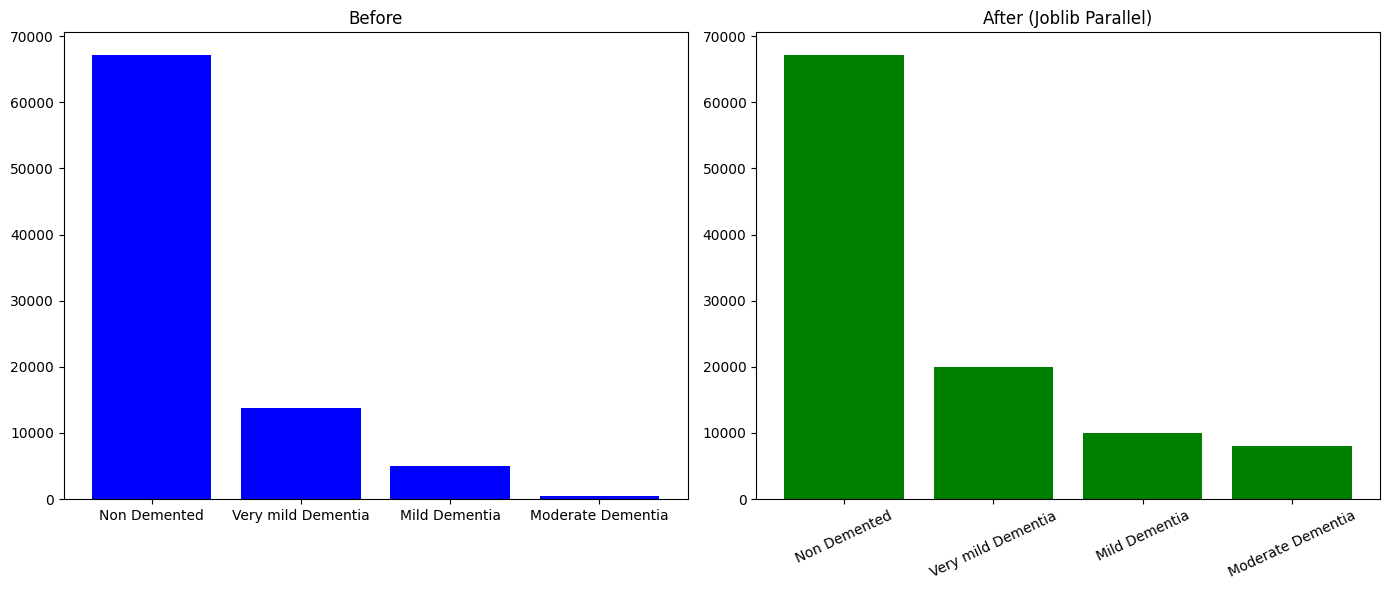

In [1]:
import os
import cv2
import random
import numpy as np
import shutil
import matplotlib.pyplot as plt

from joblib import Parallel, delayed

# -------------------------
# YOUR PATHS
# -------------------------
DATASET_DIR = r"C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Data"
OUTPUT_DIR  = r"C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Augmented_Jupyter"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# -------------------------
# YOUR CLASSES
# -------------------------
CLASSES = [
    "Non Demented",
    "Very mild Dementia",
    "Mild Dementia",
    "Moderate Dementia"
]

# -------------------------
# TARGET COUNTS
# -------------------------
TARGET_COUNTS = {
    "Non Demented": 40000,
    "Very mild Dementia": 20000,
    "Mild Dementia": 10000,
    "Moderate Dementia": 8000
}

# -------------------------
# HEAVY AUGMENTATION
# -------------------------
def heavy_aug(img):
    h, w = img.shape[:2]

    # rotation
    angle = random.randint(-20, 20)
    M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1)
    img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)

    # blur
    if random.random() < 0.7:
        k = random.choice([3,5,7])
        img = cv2.GaussianBlur(img, (k,k), 0)

    # sharpen
    if random.random() < 0.6:
        kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
        img = cv2.filter2D(img, -1, kernel)

    # brightness
    factor = random.uniform(0.7, 1.3)
    img = np.clip(img * factor, 0, 255).astype(np.uint8)

    # noise
    if random.random() < 0.6:
        noise = np.random.normal(0, 15, img.shape).astype(np.int16)
        img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    # flip
    if random.random() < 0.5:
        img = cv2.flip(img, 1)

    img = cv2.resize(img, (224,224))
    return img


def light_aug(img):
    if random.random() < 0.5:
        img = cv2.flip(img, 1)

    factor = random.uniform(0.9, 1.1)
    img = np.clip(img * factor, 0, 255).astype(np.uint8)

    img = cv2.resize(img, (224,224))
    return img


# -------------------------
# WORKER FUNCTION (joblib)
# -------------------------
def process_one(class_name, src, dst, filename, use_heavy):

    img = cv2.imread(os.path.join(src, filename))
    if img is None:
        return 0

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    if use_heavy:
        aug = heavy_aug(img)
    else:
        aug = light_aug(img)

    out = cv2.cvtColor(aug, cv2.COLOR_RGB2BGR)
    out_name = f"aug_{random.randint(0,1e12)}.jpg"
    cv2.imwrite(os.path.join(dst, out_name), out)

    return 1


# -------------------------
# MAIN LOOP PER CLASS
# -------------------------
for cls in CLASSES:

    print(f"\nProcessing: {cls}")
    src = os.path.join(DATASET_DIR, cls)
    dst = os.path.join(OUTPUT_DIR, cls)
    os.makedirs(dst, exist_ok=True)

    images = os.listdir(src)
    original = len(images)
    target   = TARGET_COUNTS[cls]

    print("Original:", original)
    print("Target:", target)

    # Copy originals
    for img in images:
        shutil.copy(os.path.join(src, img), os.path.join(dst, img))

    needed = target - original
    print("Augmenting:", needed)
    if needed <= 0:
        continue

    use_heavy = (cls != "Non Demented")

    # JOBLIB PARALLEL LOOP
    Parallel(n_jobs=-1, backend="loky")(
        delayed(process_one)(cls, src, dst, random.choice(images), use_heavy)
        for _ in range(needed)
    )


# -------------------------
# COUNT AFTER AUGMENTATION
# -------------------------
after_counts = {cls: len(os.listdir(os.path.join(OUTPUT_DIR, cls))) for cls in CLASSES}
before_counts = {cls: len(os.listdir(os.path.join(DATASET_DIR, cls))) for cls in CLASSES}

print("\nFinal Counts After Augmentation:")
print(after_counts)

# -------------------------
# PLOT GRAPHS
# -------------------------
plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
plt.bar(before_counts.keys(), before_counts.values(), color='blue')
plt.title("Before")

plt.subplot(1,2,2)
plt.bar(after_counts.keys(), after_counts.values(), color='green')
plt.title("After (Joblib Parallel)")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()



Processing Non Demented...
Original: 67222
Target: 40000
Undersampled to 40,000

Processing Very mild Dementia...
Original: 13725
Target: 20000
Augmenting needed: 6275

Processing Mild Dementia...
Original: 5002
Target: 10000
Augmenting needed: 4998

Processing Moderate Dementia...
Original: 488
Target: 8000
Augmenting needed: 7512

FINAL DISTRIBUTION:
{'Non Demented': 40000, 'Very mild Dementia': 20000, 'Mild Dementia': 10000, 'Moderate Dementia': 8000}


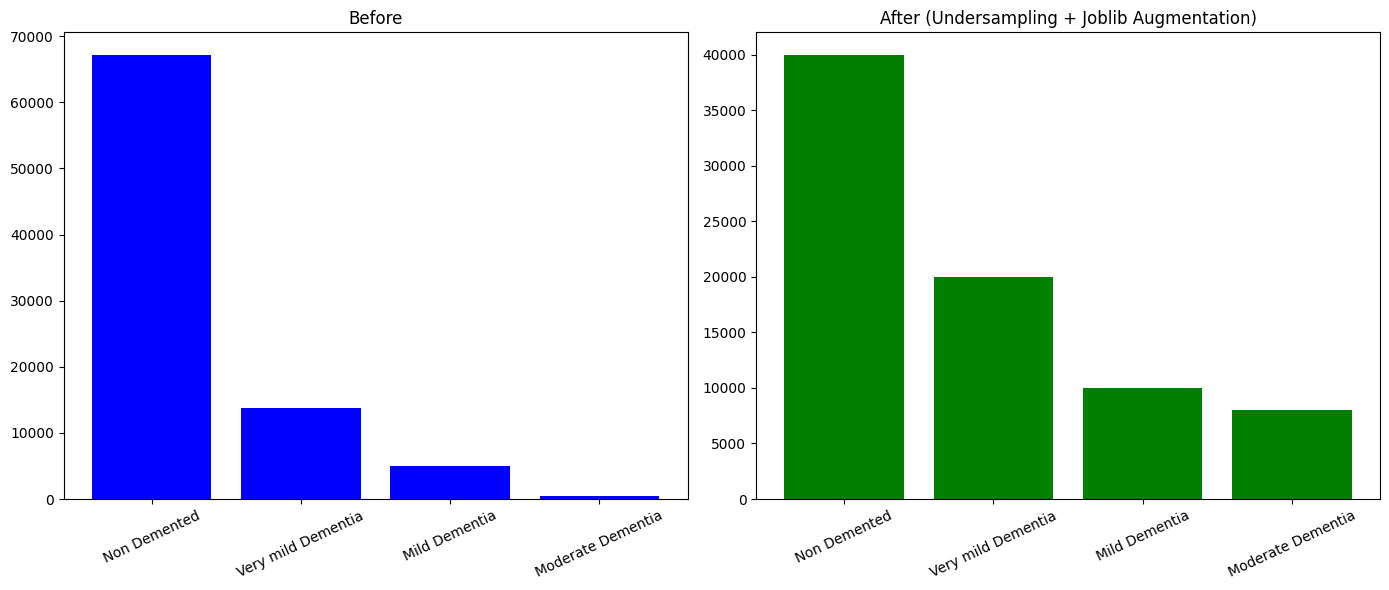

In [2]:
import os
import cv2
import random
import numpy as np
import shutil
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

# ---------------------------------------
# PATHS
# ---------------------------------------
DATASET_DIR = r"C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Data"
OUTPUT_DIR  = r"C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Processed_Final"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------------------------------
# CLASS NAMES
# ---------------------------------------
CLASSES = [
    "Non Demented",
    "Very mild Dementia",
    "Mild Dementia",
    "Moderate Dementia"
]

# ---------------------------------------
# TARGET DISTRIBUTION
# ---------------------------------------
TARGET = {
    "Non Demented": 40000,       # UNDERSAMPLE
    "Very mild Dementia": 20000, # AUGMENT
    "Mild Dementia": 10000,      # AUGMENT
    "Moderate Dementia": 8000    # AUGMENT
}

# ---------------------------------------
# HEAVY AND LIGHT AUGMENTATIONS (OpenCV)
# ---------------------------------------
def heavy_aug(img):
    h, w = img.shape[:2]

    # rotation
    angle = random.randint(-20, 20)
    M = cv2.getRotationMatrix2D((w/2, h/2), angle, 1)
    img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)

    # blur
    if random.random() < 0.7:
        k = random.choice([3,5,7])
        img = cv2.GaussianBlur(img, (k,k), 0)

    # sharpen
    if random.random() < 0.6:
        kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
        img = cv2.filter2D(img, -1, kernel)

    # brightness jitter
    factor = random.uniform(0.7, 1.3)
    img = np.clip(img * factor, 0, 255).astype(np.uint8)

    # noise
    if random.random() < 0.6:
        noise = np.random.normal(0, 15, img.shape).astype(np.int16)
        img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    # flip
    if random.random() < 0.5:
        img = cv2.flip(img, 1)

    # resize
    img = cv2.resize(img, (224, 224))
    return img


def light_aug(img):
    if random.random() < 0.5:
        img = cv2.flip(img, 1)

    factor = random.uniform(0.9, 1.1)
    img = np.clip(img * factor, 0, 255).astype(np.uint8)

    return cv2.resize(img, (224, 224))


# ---------------------------------------
# JOBLIB WORKER FOR AUGMENTATION
# ---------------------------------------
def process_aug(src, dst, filename, use_heavy):
    img = cv2.imread(os.path.join(src, filename))
    if img is None:
        return 0

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    if use_heavy:
        aug = heavy_aug(img)
    else:
        aug = light_aug(img)

    out = cv2.cvtColor(aug, cv2.COLOR_RGB2BGR)
    out_name = f"aug_{random.randint(0,1e12)}.jpg"
    cv2.imwrite(os.path.join(dst, out_name), out)

    return 1


# ---------------------------------------
# PROCESS EACH CLASS
# ---------------------------------------
for cls in CLASSES:

    print(f"\nProcessing {cls}...")
    src = os.path.join(DATASET_DIR, cls)
    dst = os.path.join(OUTPUT_DIR, cls)
    os.makedirs(dst, exist_ok=True)

    images = os.listdir(src)
    original = len(images)
    target = TARGET[cls]

    print("Original:", original)
    print("Target:", target)

    # -------------------------------
    # CASE 1: UNDERSAMPLING (Non-Demented)
    # -------------------------------
    if cls == "Non Demented":
        # random subset of 40,000
        selected = random.sample(images, target)

        for img in selected:
            shutil.copy(os.path.join(src, img), os.path.join(dst, img))

        print("Undersampled to 40,000")
        continue

    # -------------------------------
    # CASE 2: AUGMENTATION (Dementia classes)
    # -------------------------------
    # copy original images
    for img in images:
        shutil.copy(os.path.join(src, img), os.path.join(dst, img))

    needed = target - original
    print("Augmenting needed:", needed)

    if needed <= 0:
        continue

    use_heavy = (cls != "Non Demented")

    Parallel(n_jobs=-1, backend="loky")(
        delayed(process_aug)(src, dst, random.choice(images), use_heavy)
        for _ in range(needed)
    )

# ---------------------------------------
# COUNT FINAL DISTRIBUTION
# ---------------------------------------
final_counts = {
    cls: len(os.listdir(os.path.join(OUTPUT_DIR, cls)))
    for cls in CLASSES
}

print("\nFINAL DISTRIBUTION:")
print(final_counts)


# ---------------------------------------
# PLOT BEFORE / AFTER
# ---------------------------------------
before_counts = {cls: len(os.listdir(os.path.join(DATASET_DIR, cls))) for cls in CLASSES}

plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
plt.bar(before_counts.keys(), before_counts.values(), color='blue')
plt.title("Before")
plt.xticks(rotation=25)

plt.subplot(1,2,2)
plt.bar(final_counts.keys(), final_counts.values(), color='green')
plt.title("After (Undersampling + Joblib Augmentation)")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()


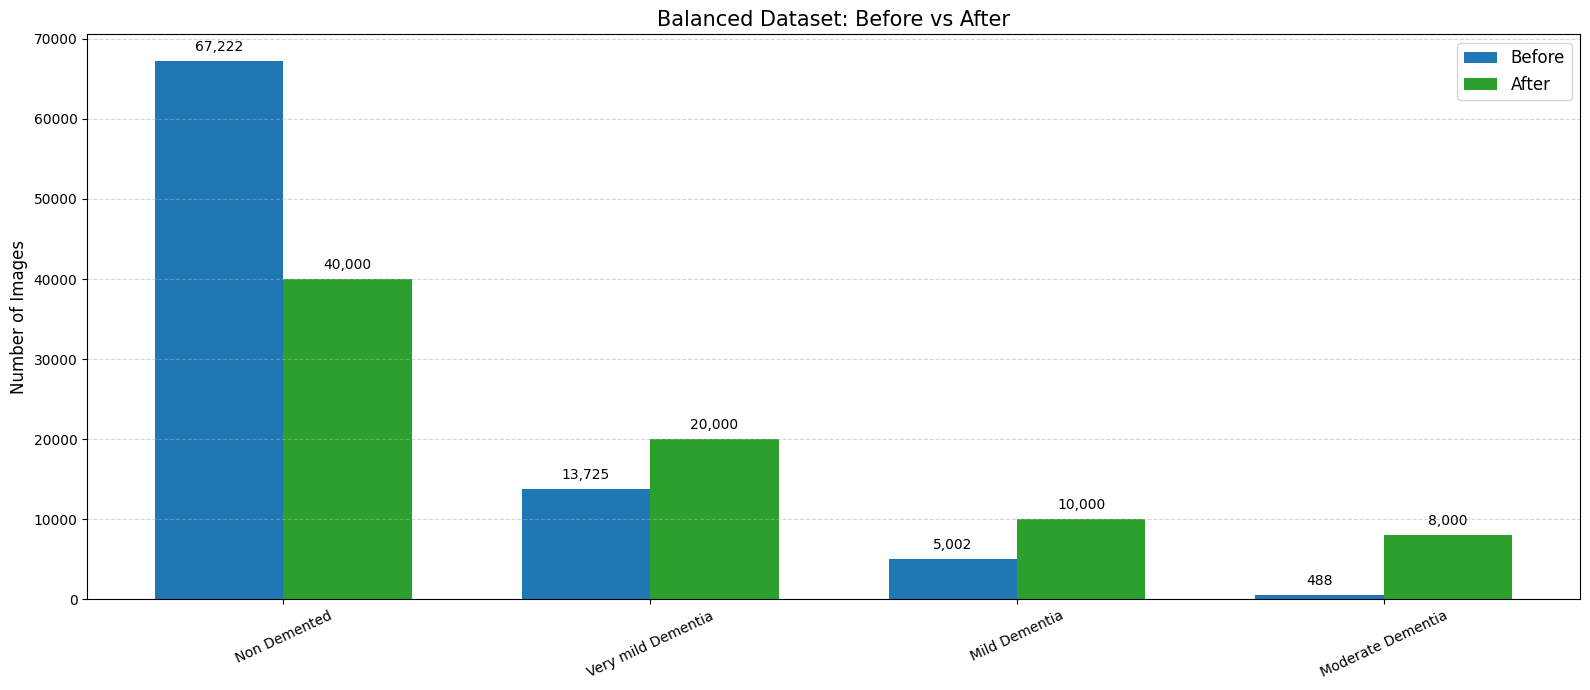

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

# ---------------------------------------
# Build BEFORE & AFTER counts
# ---------------------------------------

before_counts = {cls: len(os.listdir(os.path.join(DATASET_DIR, cls))) for cls in CLASSES}
after_counts  = {cls: len(os.listdir(os.path.join(OUTPUT_DIR, cls))) for cls in CLASSES}

classes_list = list(CLASSES)
before_vals  = [before_counts[c] for c in classes_list]
after_vals   = [after_counts[c] for c in classes_list]

x = np.arange(len(classes_list))
width = 0.35

plt.figure(figsize=(16,7))

before_bars = plt.bar(x - width/2, before_vals, width, label="Before", color='#1f77b4')
after_bars  = plt.bar(x + width/2, after_vals,  width, label="After",  color='#2ca02c')

# ---------------------------------------
# Add value labels on bars
# ---------------------------------------
def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.annotate(f'{height:,}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 5),
                     textcoords="offset points",
                     ha='center', va='bottom',
                     fontsize=10)

add_labels(before_bars)
add_labels(after_bars)

# ---------------------------------------
# Final formatting
# ---------------------------------------
plt.xticks(x, classes_list, rotation=25)
plt.ylabel("Number of Images", fontsize=12)
plt.title("Balanced Dataset: Before vs After", fontsize=15)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()
